In [22]:
from pathlib import Path
import pandas as pd

# Searches the current working directory and its module8 subfolder.
locations = [Path.cwd(), Path.cwd() / "module8", Path.cwd().parent, Path.cwd().parent / "module8"]
files = sorted({str(p.resolve()) for base in locations if base.exists() for p in base.glob("lifecyclesavings*.csv")})
if not files:
    raise FileNotFoundError(f"CSV not found. Working directory: {Path.cwd()}\nMove lifecyclesavings (1).csv into this directory or module8 folder.")
file_path = Path(files[0])
print("Loading:", file_path)
df = pd.read_csv(file_path)
print(df.head())
print("Columns:", df.columns.tolist())

Loading: C:\Users\jasmi\PycharmProjects\PythonProject\CS82A-Portfolio\lifecyclesavings (2).csv
      Contry     sr  pop15  pop75      dpi  ddpi
0  Australia  11.43  29.35   2.87  2329.68  2.87
1    Austria  12.07  23.32   4.41  1507.99  3.93
2    Belgium  13.17  23.80   4.43  2108.47  3.82
3    Bolivia   5.75  41.89   1.67   189.13  0.22
4     Brazil  12.88  42.19   0.83   728.47  4.56
Columns: ['Contry', 'sr', 'pop15', 'pop75', 'dpi', 'ddpi']


In [ ]:
# In this lab, I am learning how to use clustering to group countries based on their economic and population characteristics.

In [23]:
print("Shape (rows, columns):", df.shape)
print("\nMissing counts by column:\n", df.isna().sum())
print("\nMeans for numeric columns:\n", df.select_dtypes(include="number").mean())

Shape (rows, columns): (50, 6)

Missing counts by column:
 Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

Means for numeric columns:
 sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


In [ ]:
# I will check the number of rows and columns, identify any missing values, and calculate the mean of each numeric column.

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

features = ["sr", "pop15", "pop75", "dpi", "ddpi"]
X = df[features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster"] = model.fit_predict(X_scaled)
print("Countries in each cluster:\n", df.groupby("cluster").size())

Countries in each cluster:
 cluster
0    18
1     9
2    23
dtype: int64


In [ ]:
# I will select the numeric columns and use StandardScaler to standardize the values. This is important because the variables have different measurement scales.

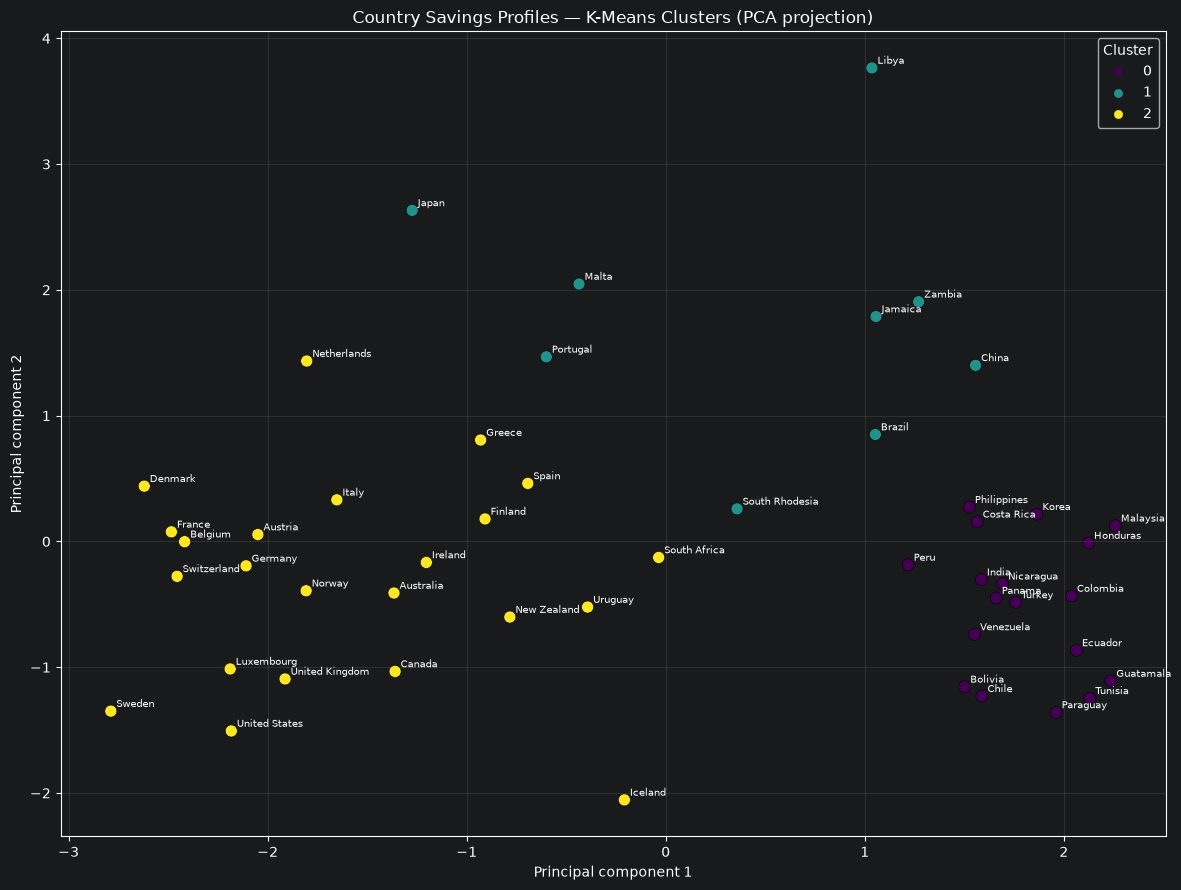

Explained variance by plotted components: [0.564 0.251]


In [25]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(12, 9))
scatter = ax.scatter(coords[:,0], coords[:,1], c=df["cluster"], cmap="viridis", s=75, edgecolor="black", linewidth=0.4)
for i, name in enumerate(df["Contry"]):
    ax.annotate(str(name), (coords[i,0], coords[i,1]), xytext=(4,3), textcoords="offset points", fontsize=7)
ax.set(title="Country Savings Profiles — K-Means Clusters (PCA projection)", xlabel="Principal component 1", ylabel="Principal component 2")
ax.legend(*scatter.legend_elements(), title="Cluster")
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
print("Explained variance by plotted components:", pca.explained_variance_ratio_.round(3))

In [ ]:
# For this analysis, I will start with three clusters to explore whether the countries can be separated into meaningful groups.

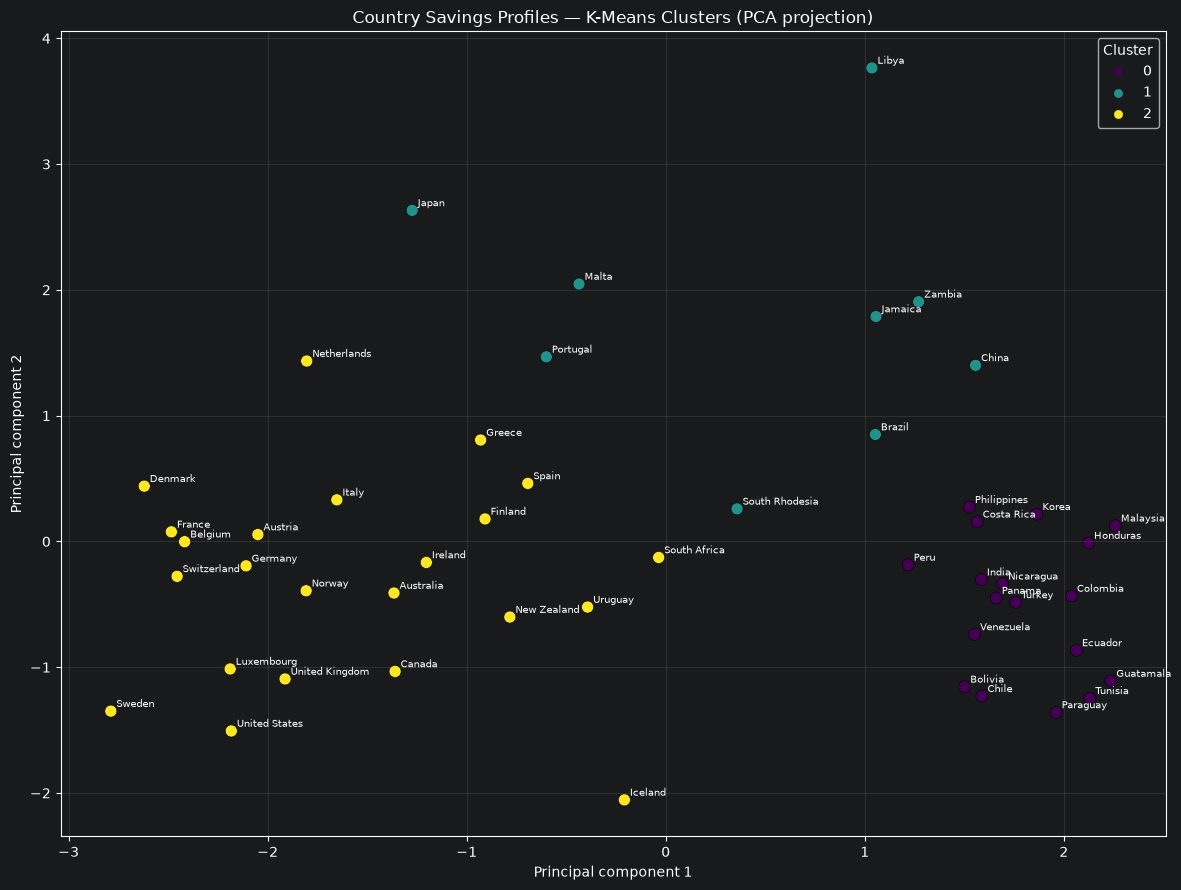

Explained variance by plotted components: [0.564 0.251]


In [26]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(12, 9))
scatter = ax.scatter(coords[:,0], coords[:,1], c=df["cluster"], cmap="viridis", s=75, edgecolor="black", linewidth=0.4)
for i, name in enumerate(df["Contry"]):
    ax.annotate(str(name), (coords[i,0], coords[i,1]), xytext=(4,3), textcoords="offset points", fontsize=7)
ax.set(title="Country Savings Profiles — K-Means Clusters (PCA projection)", xlabel="Principal component 1", ylabel="Principal component 2")
ax.legend(*scatter.legend_elements(), title="Cluster")
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
print("Explained variance by plotted components:", pca.explained_variance_ratio_.round(3))

In [ ]:
# The scatter plot compares savings rates with disposable income, and different colors represent the clusters assigned by the K-Means model.

In [27]:
# Verification scaffold: independently choose the cluster to check.
selected_cluster = 0  # Change this after inspecting your own results.
cluster_means = df.groupby("cluster")[features].mean()
overall_means = df[features].mean()
comparison = pd.DataFrame({"Selected cluster mean": cluster_means.loc[selected_cluster], "Overall mean": overall_means})
comparison["Difference"] = comparison["Selected cluster mean"] - comparison["Overall mean"]
print(comparison.round(3))

       Selected cluster mean  Overall mean  Difference
sr                     6.139         9.671      -3.532
pop15                 44.556        35.090       9.467
pop75                  1.079         2.293      -1.214
dpi                  337.153      1106.758    -769.605
ddpi                   2.359         3.758      -1.398


In [ ]:
# For this assignment, I used ChatGPT to help me understand clustering and Troubleshooting.